In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

datasets = [
    "treutlein",
    "weinreb",
    "junker",
    "you1",
    "you2",
    "you3",
    "you4",
]

normal_dir = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel_with_BH"
)


conditional_dir = ( "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/conditional_MI_celltype/conditional_mi_analysis_results_MI_label_entropy_all_genes_parallel_with_BH/")

In [2]:
results = {}

for dataset in datasets:

    normal_path = os.path.join(
        normal_dir,
        f"MI_label_entropy_{dataset}_10000_permutations_with_BH.csv"
    )

    conditional_path = os.path.join(
        conditional_dir,
        f"conditional_MI_label_entropy_{dataset}_10000_permutations_with_BH.csv"
    )

    if not os.path.exists(normal_path):
        print(f"Missing normal MI: {dataset}")
        continue

    if not os.path.exists(conditional_path):
        print(f"Missing conditional MI: {dataset}")
        continue

    normal = pd.read_csv(normal_path)
    conditional = pd.read_csv(conditional_path)

    merged = normal.merge(
        conditional,
        on="gene",
        suffixes=("_normal", "_conditional")
    )

    results[dataset] = merged

    print(
        dataset,
        len(normal),
        len(conditional),
        len(merged)
    )

treutlein 20856 20856 20856
weinreb 22636 22636 22636
junker 21062 21062 21062
you1 25349 25349 25349
you2 26854 26854 26854
you3 25990 25990 25990
you4 23286 23286 23286


In [3]:
for dataset, df in results.items():

    # Absolute change
    df["delta_MI"] = (
        df["true_mi_conditional"]
        - df["true_mi_normal"]
    )

    # Amount removed by conditioning
    df["MI_removed"] = (
        df["true_mi_normal"]
        - df["true_mi_conditional"]
    )

    # Fraction of original MI retained
    df["fraction_MI_retained"] = (
        df["true_mi_conditional"]
        / df["true_mi_normal"].replace(0, np.nan)
    )

    # Same for normalized MI
    df["delta_NMI"] = (
        df["normalized_MI_label_entropy_conditional"]
        - df["normalized_MI_label_entropy_normal"]
    )

    df["fraction_NMI_retained"] = (
        df["normalized_MI_label_entropy_conditional"]
        / df["normalized_MI_label_entropy_normal"].replace(0, np.nan)
    )

In [4]:
summary_rows = []

for dataset, df in results.items():

    valid = df[
        np.isfinite(df["true_mi_normal"]) &
        np.isfinite(df["true_mi_conditional"])
    ].copy()

    pearson_r = pearsonr(
        valid["true_mi_normal"],
        valid["true_mi_conditional"]
    )[0]

    spearman_r = spearmanr(
        valid["true_mi_normal"],
        valid["true_mi_conditional"]
    )[0]

    summary_rows.append({
        "dataset": dataset,
        "n_genes": len(valid),

        "mean_MI_normal":
            valid["true_mi_normal"].mean(),

        "mean_MI_conditional":
            valid["true_mi_conditional"].mean(),

        "median_MI_normal":
            valid["true_mi_normal"].median(),

        "median_MI_conditional":
            valid["true_mi_conditional"].median(),

        "median_fraction_MI_retained":
            valid["fraction_MI_retained"].median(),

        "pearson_r":
            pearson_r,

        "spearman_r":
            spearman_r,

        "n_sig_normal_BH":
            valid["significant_BH_FDR_0.05_normal"].sum(),

        "n_sig_conditional_BH":
            valid["significant_BH_FDR_0.05_conditional"].sum(),
    })

comparison_summary = pd.DataFrame(summary_rows)

comparison_summary.round(3)

,dataset,n_genes,mean_MI_normal,mean_MI_conditional,median_MI_normal,median_MI_conditional,median_fraction_MI_retained,pearson_r,spearman_r,n_sig_normal_BH,n_sig_conditional_BH
0,treutlein,20856,0.339,0.425,0.205,0.238,1.161,0.998,0.999,12322,11575
1,weinreb,22636,0.204,0.237,0.032,0.032,1.014,0.997,1.000,7582,7032
2,junker,21062,0.073,0.147,0.036,0.043,1.180,0.971,0.997,514,0
3,you1,25349,0.878,0.877,0.290,0.284,0.987,1.000,1.000,12939,11524
4,you2,26854,0.761,0.779,0.250,0.249,1.005,1.000,1.000,16567,14950
5,you3,25990,0.736,0.759,0.283,0.282,1.007,0.999,1.000,9793,9361
6,you4,23286,0.890,0.891,0.470,0.452,0.958,0.998,0.999,6549,6306


In [5]:
name_map = {
    # names used in MI results
    "treutlein": "HBO1",
    "weinreb": "MHSPC",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "morris_rna": "Morris RNA",
    "morris_atac": "Morris ATAC",

    # names used in dataset_summary
    "treutlein_all_genes": "HBO1",
    "weinreb_all_genes": "MHSPC",
    "junker_z5_all_genes": "ZFL",
    "you_stage1_barcode_all_genes": "HBO3_1",
    "you_stage2_barcode_all_genes": "HBO3_2",
    "you_stage3_barcode_all_genes": "HBO3_3",
    "you_stage4_barcode_all_genes": "HBO3_4",
}

In [6]:
from pathlib import Path
import pickle
from scipy.stats import chi2_contingency

# Same preprocessing folder as before
base_dir = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/")

file_dict = {
    "treutlein": base_dir / "treutlein_all_genes.pkl",
    "weinreb": base_dir / "weinreb_all_genes.pkl",
    "junker": base_dir / "junker_z5_all_genes.pkl",
    "you1": base_dir / "you_stage1_barcode_all_genes.pkl",
    "you2": base_dir / "you_stage2_barcode_all_genes.pkl",
    "you3": base_dir / "you_stage3_barcode_all_genes.pkl",
    "you4": base_dir / "you_stage4_barcode_all_genes.pkl",
}


def cramers_v_corrected(x, y):
    """
    Bias-corrected Cramér's V.
    """

    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(
        confusion_matrix,
        correction=False
    )[0]

    n = confusion_matrix.values.sum()
    r, k = confusion_matrix.shape

    phi2 = chi2 / n

    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denom = min(
        k_corr - 1,
        r_corr - 1
    )

    if denom <= 0:
        return np.nan

    return np.sqrt(
        phi2_corr / denom
    )


cramer_rows = []

for dataset in datasets:

    with open(file_dict[dataset], "rb") as f:
        df = pickle.load(f)

    # Your current file format:
    # second-last column = cell type
    # last column = lineage barcode
    cell_types = df.iloc[:, -2]
    lineages = df.iloc[:, -1]

    v = cramers_v_corrected(
        lineages,
        cell_types
    )

    cramer_rows.append({
        "dataset": dataset,
        "cramers_v": v
    })


cramer_df = pd.DataFrame(cramer_rows)

cramer_df["display_name"] = (
    cramer_df["dataset"]
    .map(name_map)
    .fillna(cramer_df["dataset"])
)

cramer_df.round(3)

,dataset,cramers_v,display_name
0,treutlein,0.440,HBO1
1,weinreb,0.619,MHSPC
2,junker,0.190,ZFL
3,you1,0.224,HBO3_1
4,you2,0.274,HBO3_2
5,you3,0.356,HBO3_3
6,you4,0.387,HBO3_4


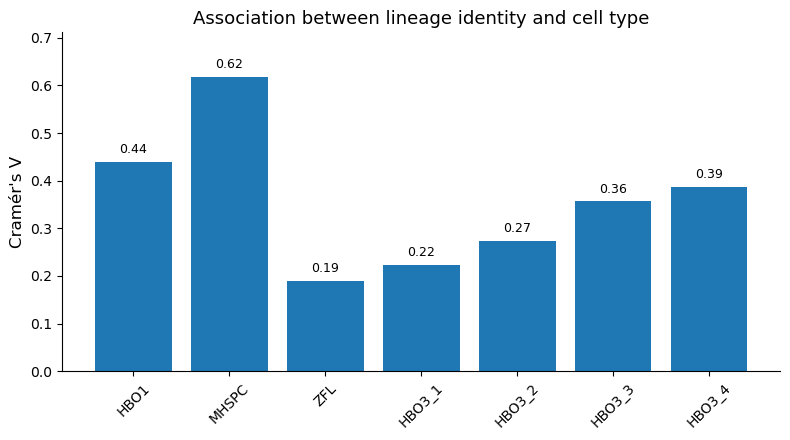

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    cramer_df["display_name"],
    cramer_df["cramers_v"]
)

ax.set_ylabel("Cramér's V", fontsize=12)
ax.set_xlabel("")

ax.set_title(
    "Association between lineage identity and cell type",
    fontsize=13
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    rotation=45
)

for bar, value in zip(
    bars,
    cramer_df["cramers_v"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.012,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(
    0,
    cramer_df["cramers_v"].max() * 1.15
)

plt.tight_layout()
plt.savefig(
    '/fast/AG_Metzger/philipp/python_files/'
    'gene_signature/mutual_information_approach/'
    'November_25_ReDo/figures/'
    'cramers_v.pdf',
    bbox_inches='tight'
)
plt.show()

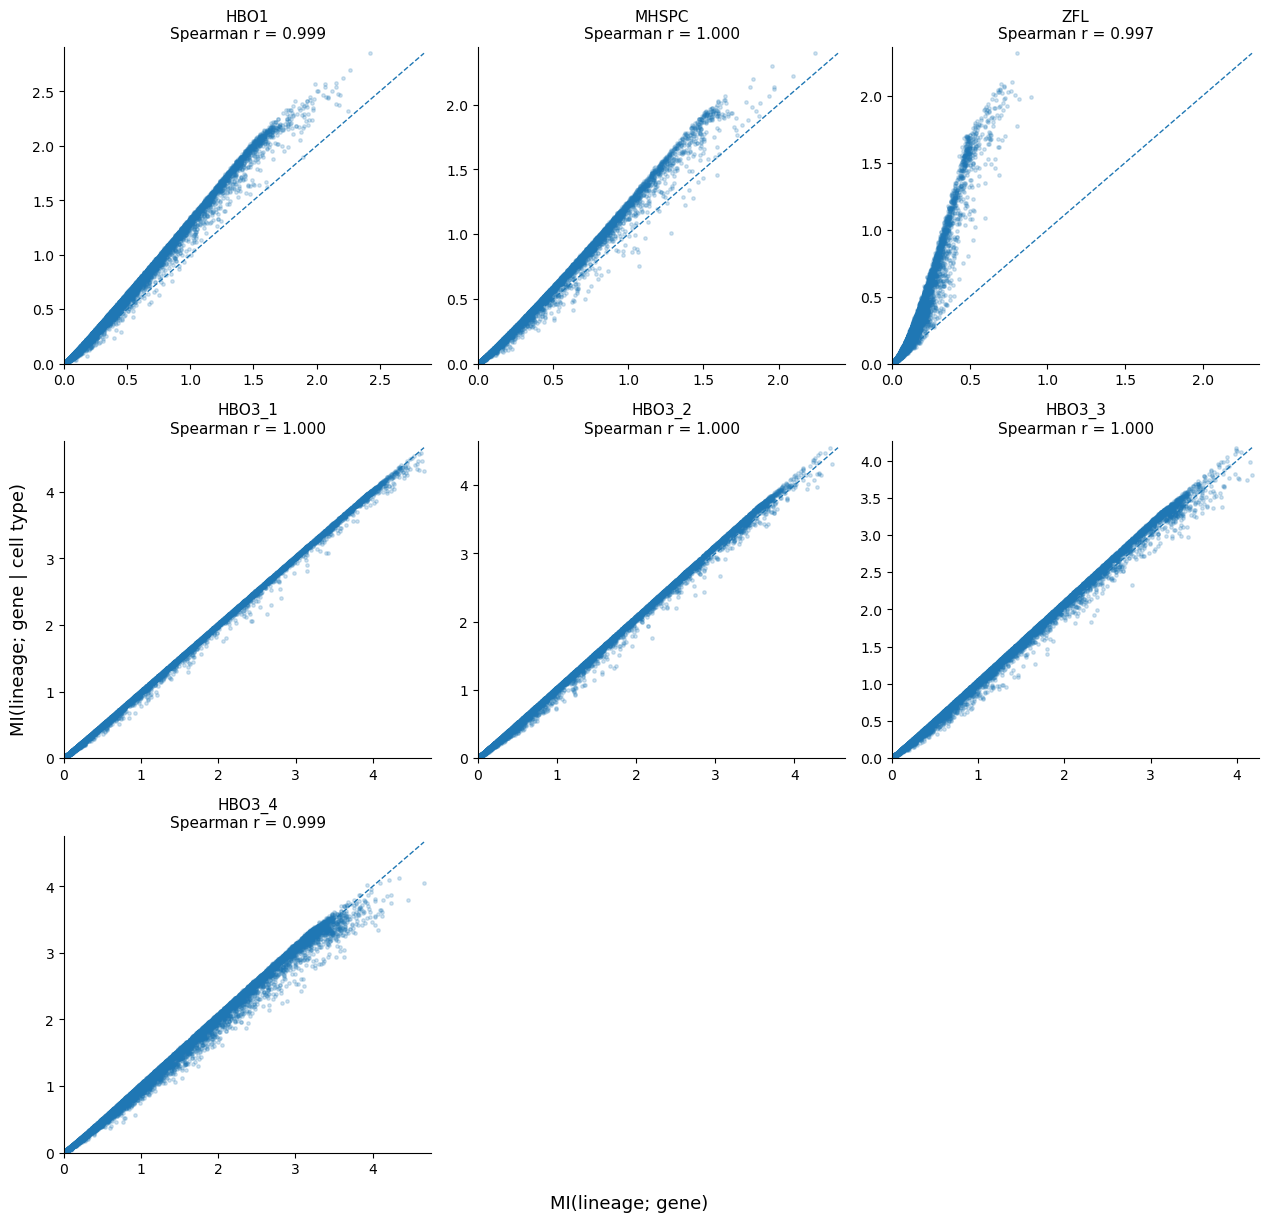

In [8]:
available_datasets = [
    dataset for dataset in datasets
    if dataset in results
]

ncols = 3
nrows = int(np.ceil(len(available_datasets) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4.3 * ncols, 4.1 * nrows),
    squeeze=False
)

axes = axes.flatten()

for ax, dataset in zip(axes, available_datasets):

    df = results[dataset].dropna(
        subset=[
            "true_mi_normal",
            "true_mi_conditional"
        ]
    ).copy()

    # Correlations
    pearson_r = pearsonr(
        df["true_mi_normal"],
        df["true_mi_conditional"]
    )[0]

    spearman_r = spearmanr(
        df["true_mi_normal"],
        df["true_mi_conditional"]
    )[0]

    # Same scale on both axes
    max_val = max(
        df["true_mi_normal"].max(),
        df["true_mi_conditional"].max()
    )

    # Genes
    ax.scatter(
        df["true_mi_normal"],
        df["true_mi_conditional"],
        s=6,
        alpha=0.2,
        rasterized=True
    )

    # Identity line: conditional MI = normal MI
    ax.plot(
        [0, max_val],
        [0, max_val],
        linestyle="--",
        linewidth=1
    )

    ax.set_xlim(0, max_val * 1.02)
    ax.set_ylim(0, max_val * 1.02)

    ax.set_title(
        f"{name_map.get(dataset, dataset)}\n"
        f"Spearman r = {spearman_r:.3f}",
        fontsize=11
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# Remove empty panels
for ax in axes[len(available_datasets):]:
    ax.remove()


fig.supxlabel(
    "MI(lineage; gene)",
    fontsize=13
)

fig.supylabel(
    "MI(lineage; gene | cell type)",
    fontsize=13
)

plt.tight_layout()
plt.savefig(
    '/fast/AG_Metzger/philipp/python_files/'
    'gene_signature/mutual_information_approach/'
    'November_25_ReDo/figures/'
    'scatter_CMI_vs_NMI.pdf',
    bbox_inches='tight'
)
plt.show()

sanity checks:

In [9]:
for dataset, df in results.items():

    diff = (
        df["true_mi_conditional"]
        - df["true_mi_normal"]
    )

    print(
        dataset,
        "exactly equal:",
        np.all(
            df["true_mi_conditional"].values
            == df["true_mi_normal"].values
        ),
        "mean abs diff:",
        np.mean(np.abs(diff)),
        "max abs diff:",
        np.max(np.abs(diff))
    )

treutlein exactly equal: False mean abs diff: 0.08714457606113822 max abs diff: 0.5841500609507864
weinreb exactly equal: False mean abs diff: 0.0340382703272154 max abs diff: 0.43157517199534423
junker exactly equal: False mean abs diff: 0.0741797144858399 max abs diff: 1.5128181600182247
you1 exactly equal: False mean abs diff: 0.008077164983543848 max abs diff: 0.46204714989926154
you2 exactly equal: False mean abs diff: 0.023645712909072743 max abs diff: 0.4387259981552407
you3 exactly equal: False mean abs diff: 0.031144461586093804 max abs diff: 0.47516543435259306
you4 exactly equal: False mean abs diff: 0.03162249072778374 max abs diff: 0.7304982073594557


In [10]:
from scipy.stats import linregress

rows = []

for dataset, df in results.items():

    valid = df.dropna(
        subset=[
            "true_mi_normal",
            "true_mi_conditional"
        ]
    )

    fit = linregress(
        valid["true_mi_normal"],
        valid["true_mi_conditional"]
    )

    rows.append({
        "dataset": dataset,
        "slope": fit.slope,
        "intercept": fit.intercept,
        "r2": fit.rvalue**2
    })

pd.DataFrame(rows).round(4)

,dataset,slope,intercept,r2
0,treutlein,1.2972,-0.0151,0.9958
1,weinreb,1.1935,-0.0072,0.9950
2,junker,2.6890,-0.0499,0.9436
3,you1,1.0038,-0.0034,0.9997
4,you2,1.0298,-0.0046,0.9993
5,you3,1.0374,-0.0048,0.9984
6,you4,1.0103,-0.0090,0.9968


In [11]:
import os
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import mutual_info_score


# ============================================================
# PATHS
# ============================================================

BASE = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "preprocessing"
)

# NORMAL MI MUST USE THIS FOLDER:
# [genes ... | barcode]
OLD_DIR = BASE / "pkl_files_filtered"

# CONDITIONAL MI MUST USE THIS FOLDER:
# [genes ... | cell type | barcode]
NEW_DIR = BASE / "pkl_files_filtered_with_celltype"


file_dict = {
    "treutlein": "treutlein_all_genes.pkl",
    "weinreb": "weinreb_all_genes.pkl",
    "junker": "junker_z5_all_genes.pkl",
    "you1": "you_stage1_barcode_all_genes.pkl",
    "you2": "you_stage2_barcode_all_genes.pkl",
    "you3": "you_stage3_barcode_all_genes.pkl",
    "you4": "you_stage4_barcode_all_genes.pkl",
}


# ============================================================
# INDEPENDENT INFORMATION-THEORY FUNCTIONS
# ============================================================

def mi_bits(expression, lineage):
    """
    Independent normal MI:
        I(lineage; gene)
    Same 0.1 rounding as original analysis.
    """

    expression = np.round(
        np.asarray(expression),
        1
    ).astype(np.float32)

    return (
        mutual_info_score(
            lineage,
            expression
        )
        / np.log(2)
    )


def cmi_direct_bits(expression, lineage, celltype):
    """
    Direct definition:

        I(X;Y|C)
        = sum_c P(c) I(X;Y | C=c)
    """

    expression = np.asarray(expression)
    lineage = np.asarray(lineage)
    celltype = np.asarray(celltype)

    n = len(expression)

    cmi = 0.0

    for c in np.unique(celltype):

        mask = celltype == c

        cmi += (
            mask.sum() / n
        ) * mi_bits(
            expression[mask],
            lineage[mask]
        )

    return cmi


def entropy_bits(labels):
    _, counts = np.unique(
        labels,
        return_counts=True
    )

    p = counts / counts.sum()

    return -np.sum(
        p * np.log2(p)
    )


def joint_codes(*variables):
    """
    Create one categorical code for arbitrary joint states.
    Used only for independent validation.
    """

    arrays = [
        np.asarray(v)
        for v in variables
    ]

    tuples = list(zip(*arrays))

    codes, _ = pd.factorize(
        tuples,
        sort=False
    )

    return codes


def cmi_entropy_bits(expression, lineage, celltype):
    """
    Independent entropy-identity calculation:

        I(X;Y|C)
        = H(X,C) + H(Y,C)
          - H(C) - H(X,Y,C)
    """

    expression = np.round(
        np.asarray(expression),
        1
    ).astype(np.float32)

    lineage = np.asarray(lineage)
    celltype = np.asarray(celltype)

    H_XC = entropy_bits(
        joint_codes(
            lineage,
            celltype
        )
    )

    H_YC = entropy_bits(
        joint_codes(
            expression,
            celltype
        )
    )

    H_C = entropy_bits(
        celltype
    )

    H_XYC = entropy_bits(
        joint_codes(
            lineage,
            expression,
            celltype
        )
    )

    return (
        H_XC
        + H_YC
        - H_C
        - H_XYC
    )


# ============================================================
# VALIDATE ALL DATASETS
# ============================================================

format_rows = []
validation_rows = []


for dataset, filename in file_dict.items():

    print("\n" + "=" * 80)
    print(dataset)
    print("=" * 80)

    old_path = OLD_DIR / filename
    new_path = NEW_DIR / filename

    assert old_path.exists(), f"Missing OLD file: {old_path}"
    assert new_path.exists(), f"Missing NEW file: {new_path}"


    with open(old_path, "rb") as f:
        old_df = pickle.load(f)

    with open(new_path, "rb") as f:
        new_df = pickle.load(f)


    # ========================================================
    # FORMAT DEFINITIONS
    # ========================================================

    # OLD:
    # genes = everything except last column
    # barcode = last column

    old_gene_cols = list(
        old_df.columns[:-1]
    )

    old_barcode_col = (
        old_df.columns[-1]
    )


    # NEW:
    # genes = everything except final TWO columns
    # cell type = second-last
    # barcode = last

    new_gene_cols = list(
        new_df.columns[:-2]
    )

    celltype_col = (
        new_df.columns[-2]
    )

    new_barcode_col = (
        new_df.columns[-1]
    )


    # ========================================================
    # HARD SAFETY CHECKS
    # ========================================================

    # New file should have exactly one extra column
    assert (
        new_df.shape[1]
        == old_df.shape[1] + 1
    ), (
        f"{dataset}: New file should contain exactly "
        "one additional column (cell type).\n"
        f"OLD columns = {old_df.shape[1]}\n"
        f"NEW columns = {new_df.shape[1]}"
    )


    # Gene columns must be IDENTICAL
    assert (
        old_gene_cols == new_gene_cols
    ), (
        f"{dataset}: Gene columns differ between "
        "old and cell-type annotated files!"
    )


    # Barcode should still be final column
    assert (
        old_barcode_col == new_barcode_col
    ), (
        f"{dataset}: Barcode column changed!\n"
        f"OLD: {old_barcode_col}\n"
        f"NEW: {new_barcode_col}"
    )


    # Number of cells must be identical
    assert (
        len(old_df) == len(new_df)
    ), (
        f"{dataset}: Number of cells differs!\n"
        f"OLD = {len(old_df)}\n"
        f"NEW = {len(new_df)}"
    )


    # Barcode values/order must be identical
    assert np.array_equal(
        old_df.iloc[:, -1].values,
        new_df.iloc[:, -1].values
    ), (
        f"{dataset}: Barcode values or row order differ "
        "between old and new files!"
    )


    # Explicitly make sure cell type is NOT counted as a gene
    assert (
        celltype_col not in old_gene_cols
    ), (
        f"{dataset}: Cell-type column '{celltype_col}' "
        "was found among OLD gene columns!"
    )


    print("OLD format:")
    print(
        f"  {len(old_gene_cols):,} genes | "
        f"barcode = '{old_barcode_col}'"
    )

    print("NEW format:")
    print(
        f"  {len(new_gene_cols):,} genes | "
        f"cell type = '{celltype_col}' | "
        f"barcode = '{new_barcode_col}'"
    )

    print(
        f"  cells = {len(new_df):,}, "
        f"cell types = {new_df[celltype_col].nunique():,}, "
        f"lineages = {new_df[new_barcode_col].nunique():,}"
    )

    print(
        "  example cell types:",
        new_df[celltype_col]
        .drop_duplicates()
        .head(5)
        .tolist()
    )


    format_rows.append({
        "dataset": dataset,
        "n_cells": len(new_df),
        "n_genes": len(new_gene_cols),
        "n_celltypes":
            new_df[celltype_col].nunique(),
        "n_lineages":
            new_df[new_barcode_col].nunique(),
        "celltype_column": celltype_col,
        "barcode_column": new_barcode_col,
        "format_OK": True
    })


    # ========================================================
    # TEST SOME GENES
    #
    # Prefer top normal-MI genes if current results exist;
    # otherwise simply use first five genes.
    # ========================================================

    if (
        "results" in globals()
        and dataset in results
    ):

        test_genes = (
            results[dataset]
            .sort_values(
                "true_mi_normal",
                ascending=False
            )
            ["gene"]
            .head(5)
            .tolist()
        )

    else:

        test_genes = (
            old_gene_cols[:5]
        )


    for gene in test_genes:

        # --------------------------------------------
        # NORMAL MI FROM OLD FORMAT
        # --------------------------------------------

        normal_old = mi_bits(
            old_df[gene].values,
            old_df[old_barcode_col].values
        )


        # --------------------------------------------
        # NORMAL MI FROM NEW FORMAT
        #
        # Important:
        # cell type is explicitly NOT included.
        # --------------------------------------------

        normal_new = mi_bits(
            new_df[gene].values,
            new_df[new_barcode_col].values
        )


        # --------------------------------------------
        # CONDITIONAL MI FROM NEW FILE ONLY
        # direct weighted calculation
        # --------------------------------------------

        cmi_direct = cmi_direct_bits(
            new_df[gene].values,
            new_df[new_barcode_col].values,
            new_df[celltype_col].values
        )


        # --------------------------------------------
        # CONDITIONAL MI SECOND INDEPENDENT METHOD
        # entropy identity
        # --------------------------------------------

        cmi_entropy = cmi_entropy_bits(
            new_df[gene].values,
            new_df[new_barcode_col].values,
            new_df[celltype_col].values
        )


        validation_rows.append({
            "dataset": dataset,
            "gene": gene,

            "normal_MI_old_file":
                normal_old,

            "normal_MI_new_file":
                normal_new,

            "normal_old_vs_new_diff":
                normal_old - normal_new,

            "CMI_direct":
                cmi_direct,

            "CMI_entropy":
                cmi_entropy,

            "CMI_method_diff":
                cmi_direct - cmi_entropy,
        })


# ============================================================
# OUTPUT
# ============================================================

format_check = pd.DataFrame(
    format_rows
)

validation_check = pd.DataFrame(
    validation_rows
)


print("\n\n")
print("=" * 80)
print("FILE FORMAT CHECK")
print("=" * 80)

display(
    format_check
)


print("\n")
print("=" * 80)
print("MI / CMI VALIDATION")
print("=" * 80)

display(
    validation_check.round(10)
)


print("\n")
print("=" * 80)
print("MAXIMUM NUMERICAL DIFFERENCES")
print("=" * 80)

print(
    "Normal MI old file vs new file:",
    validation_check[
        "normal_old_vs_new_diff"
    ].abs().max()
)

print(
    "Direct CMI vs entropy-identity CMI:",
    validation_check[
        "CMI_method_diff"
    ].abs().max()
)


treutlein
OLD format:
  20,856 genes | barcode = 'barcode_cont'
NEW format:
  20,856 genes | cell type = 'cell_type' | barcode = 'barcode_cont'
  cells = 16,506, cell types = 13, lineages = 3,905
  example cell types: ['choroid_plexus', 'dien_neuron', 'dien_NPC', 'tel_NPC', 'retina']


/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass v

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass v


weinreb
OLD format:
  22,636 genes | barcode = 'barcode_cont'
NEW format:
  22,636 genes | cell type = 'cell_type' | barcode = 'barcode_cont'
  cells = 49,302, cell types = 11, lineages = 5,864
  example cell types: ['Undifferentiated', 'Monocyte', 'Neutrophil', 'Baso', 'Erythroid']


/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass v

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/sklearn/metrics/cluster/_supervised.py:66: UserWarning: Clustering metrics expects discrete values but received multiclass v

... (13 outputs left out)

,dataset,n_cells,n_genes,n_celltypes,n_lineages,celltype_column,barcode_column,format_OK
0,treutlein,16506,20856,13,3905,cell_type,barcode_cont,True
1,weinreb,49302,22636,11,5864,cell_type,barcode_cont,True
2,junker,6191,21062,33,210,cell_type,barcode_cont,True
3,you1,18650,25349,6,17075,cell_type,barcode_cont,True
4,you2,42640,26854,9,33308,cell_type,barcode_cont,True
5,you3,23883,25990,7,15792,cell_type,barcode_cont,True
6,you4,2864,23286,10,2004,cell_type,barcode_cont,True




MI / CMI VALIDATION


,dataset,gene,normal_MI_old_file,normal_MI_new_file,normal_old_vs_new_diff,CMI_direct,CMI_entropy,CMI_method_diff
0,treutlein,MT-ND3,2.424044,2.424044,0.0,2.850079,2.850079,0.0
1,treutlein,MT-ATP6,2.262028,2.262028,0.0,2.699499,2.699499,0.0
2,treutlein,eGFP,2.247599,2.247599,0.0,2.318668,2.318668,0.0
3,treutlein,MT-CO3,2.206211,2.206211,0.0,2.621203,2.621203,0.0
4,treutlein,VIM,2.188112,2.188112,0.0,2.467394,2.467394,0.0
5,weinreb,Srgn,2.240673,2.240673,0.0,2.396029,2.396029,0.0
6,weinreb,Fth1,2.094501,2.094501,0.0,2.221644,2.221644,0.0
7,weinreb,H2afy,1.972067,1.972067,0.0,2.139279,2.139279,0.0
8,weinreb,Tmsb4x,1.970007,1.970007,0.0,2.123166,2.123166,0.0
9,weinreb,Ifitm1,1.955551,1.955551,0.0,2.297154,2.297154,0.0




MAXIMUM NUMERICAL DIFFERENCES
Normal MI old file vs new file: 0.0
Direct CMI vs entropy-identity CMI: 4.440892098500626e-15


In [12]:
# ============================================================
# CHECK SAVED RESULT FILES AGAINST INDEPENDENT CALCULATIONS
# ============================================================

normal_results_dir = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel_with_BH"
)

conditional_results_dir = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "calc_files/MI/conditional_MI_celltype/"
    "conditional_mi_analysis_results_MI_label_entropy_all_genes_parallel_with_BH"
)

num_permutations = 10000

result_validation_rows = []


for dataset in validation_check["dataset"].unique():

    print("\n" + "=" * 80)
    print(dataset)
    print("=" * 80)

    normal_path = (
        normal_results_dir
        / f"MI_label_entropy_{dataset}_{num_permutations}_permutations_with_BH.csv"
    )

    conditional_path = (
        conditional_results_dir
        / f"conditional_MI_label_entropy_{dataset}_{num_permutations}_permutations_with_BH.csv"
    )

    if not normal_path.exists():
        print(f"Missing normal result file:\n{normal_path}")
        continue

    if not conditional_path.exists():
        print(f"Missing conditional result file:\n{conditional_path}")
        continue


    # --------------------------------------------------------
    # Load result CSVs
    # --------------------------------------------------------

    normal_results = pd.read_csv(normal_path)
    conditional_results = pd.read_csv(conditional_path)


    # --------------------------------------------------------
    # Load annotated PKL only to calculate H(lineage)
    # for checking normalized MI as well
    # --------------------------------------------------------

    filename = file_dict[dataset]

    with open(NEW_DIR / filename, "rb") as f:
        annotated_df = pickle.load(f)

    lineage = annotated_df.iloc[:, -1].values

    H_lineage = entropy_bits(lineage)


    # --------------------------------------------------------
    # Independent values already calculated in validation_check
    # --------------------------------------------------------

    dataset_validation = validation_check[
        validation_check["dataset"] == dataset
    ]


    for _, test_row in dataset_validation.iterrows():

        gene = test_row["gene"]

        normal_match = normal_results[
            normal_results["gene"] == gene
        ]

        conditional_match = conditional_results[
            conditional_results["gene"] == gene
        ]

        if len(normal_match) != 1:
            print(
                f"WARNING: {gene}: "
                f"{len(normal_match)} matches in normal results"
            )
            continue

        if len(conditional_match) != 1:
            print(
                f"WARNING: {gene}: "
                f"{len(conditional_match)} matches in conditional results"
            )
            continue


        normal_row = normal_match.iloc[0]
        conditional_row = conditional_match.iloc[0]


        # Independent expected values
        expected_normal = test_row["normal_MI_old_file"]
        expected_cmi = test_row["CMI_direct"]

        expected_normal_nmi = (
            expected_normal / (H_lineage + 1e-9)
        )

        expected_cmi_nmi = (
            expected_cmi / (H_lineage + 1e-9)
        )


        # Saved values
        saved_normal = normal_row["true_mi"]
        saved_cmi = conditional_row["true_mi"]

        saved_normal_nmi = (
            normal_row["normalized_MI_label_entropy"]
        )

        saved_cmi_nmi = (
            conditional_row["normalized_MI_label_entropy"]
        )


        result_validation_rows.append({

            "dataset": dataset,
            "gene": gene,

            # Raw normal MI
            "expected_normal_MI": expected_normal,
            "saved_normal_MI": saved_normal,
            "normal_MI_diff":
                saved_normal - expected_normal,

            # Raw conditional MI
            "expected_CMI": expected_cmi,
            "saved_CMI": saved_cmi,
            "CMI_diff":
                saved_cmi - expected_cmi,

            # Normalized normal MI
            "expected_normal_NMI": expected_normal_nmi,
            "saved_normal_NMI": saved_normal_nmi,
            "normal_NMI_diff":
                saved_normal_nmi - expected_normal_nmi,

            # Normalized conditional MI
            "expected_conditional_NMI": expected_cmi_nmi,
            "saved_conditional_NMI": saved_cmi_nmi,
            "conditional_NMI_diff":
                saved_cmi_nmi - expected_cmi_nmi,
        })


# ============================================================
# SUMMARY
# ============================================================

result_validation = pd.DataFrame(
    result_validation_rows
)

display(
    result_validation.round(12)
)


print("\n" + "=" * 80)
print("MAXIMUM ABSOLUTE DIFFERENCES")
print("=" * 80)

for col in [
    "normal_MI_diff",
    "CMI_diff",
    "normal_NMI_diff",
    "conditional_NMI_diff"
]:
    print(
        f"{col}: "
        f"{result_validation[col].abs().max():.3e}"
    )


# ============================================================
# SIMPLE PASS / FAIL
# ============================================================

tolerance = 1e-8

normal_ok = (
    result_validation["normal_MI_diff"]
    .abs()
    .max()
    < tolerance
)

cmi_ok = (
    result_validation["CMI_diff"]
    .abs()
    .max()
    < tolerance
)

normal_nmi_ok = (
    result_validation["normal_NMI_diff"]
    .abs()
    .max()
    < tolerance
)

conditional_nmi_ok = (
    result_validation["conditional_NMI_diff"]
    .abs()
    .max()
    < tolerance
)


print("\n" + "=" * 80)
print("VALIDATION RESULT")
print("=" * 80)

print("Normal MI result files:       ", "PASS" if normal_ok else "FAIL")
print("Conditional MI result files:  ", "PASS" if cmi_ok else "FAIL")
print("Normal NMI result files:      ", "PASS" if normal_nmi_ok else "FAIL")
print("Conditional NMI result files: ", "PASS" if conditional_nmi_ok else "FAIL")


treutlein

weinreb

junker

you1

you2

you3

you4


,dataset,gene,expected_normal_MI,saved_normal_MI,normal_MI_diff,expected_CMI,saved_CMI,CMI_diff,expected_normal_NMI,saved_normal_NMI,normal_NMI_diff,expected_conditional_NMI,saved_conditional_NMI,conditional_NMI_diff
0,treutlein,MT-ND3,2.424044,2.424044,0.0,2.850079,2.850079,1.900000e-11,0.255378,0.255378,1.520000e-10,0.300262,0.300262,1.800000e-10
1,treutlein,MT-ATP6,2.262028,2.262028,-0.0,2.699499,2.699499,1.900000e-11,0.238309,0.238309,1.410000e-10,0.284398,0.284398,1.710000e-10
2,treutlein,eGFP,2.247599,2.247599,-0.0,2.318668,2.318668,1.900000e-11,0.236789,0.236789,1.410000e-10,0.244276,0.244276,1.470000e-10
3,treutlein,MT-CO3,2.206211,2.206211,-0.0,2.621203,2.621203,1.900000e-11,0.232429,0.232429,1.380000e-10,0.276149,0.276149,1.660000e-10
4,treutlein,VIM,2.188112,2.188112,-0.0,2.467394,2.467394,1.900000e-11,0.230522,0.230522,1.370000e-10,0.259945,0.259945,1.560000e-10
5,weinreb,Srgn,2.240673,2.240673,-0.0,2.396029,2.396029,2.900000e-11,0.191217,0.191217,1.380000e-10,0.204475,0.204475,1.500000e-10
6,weinreb,Fth1,2.094501,2.094501,0.0,2.221644,2.221644,2.900000e-11,0.178743,0.178743,1.290000e-10,0.189594,0.189594,1.390000e-10
7,weinreb,H2afy,1.972067,1.972067,0.0,2.139279,2.139279,2.800000e-11,0.168295,0.168295,1.220000e-10,0.182565,0.182565,1.340000e-10
8,weinreb,Tmsb4x,1.970007,1.970007,0.0,2.123166,2.123166,2.900000e-11,0.168119,0.168119,1.210000e-10,0.181190,0.181190,1.330000e-10
9,weinreb,Ifitm1,1.955551,1.955551,0.0,2.297154,2.297154,2.900000e-11,0.166885,0.166885,1.200000e-10,0.196038,0.196038,1.440000e-10



MAXIMUM ABSOLUTE DIFFERENCES
normal_MI_diff: 4.352e-13
CMI_diff: 4.849e-11
normal_NMI_diff: 9.928e-10
conditional_NMI_diff: 1.011e-09

VALIDATION RESULT
Normal MI result files:        PASS
Conditional MI result files:   PASS
Normal NMI result files:       PASS
Conditional NMI result files:  PASS


# making MI plot with MT genes etc again

In [13]:
# =========================================================
# Prepare conditional CMI data for Figure 2B
# =========================================================

dataset_labels = {
    "treutlein": "HBO1",
    "weinreb": "MHSPC",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}

conditional_plot_dfs = []

for dataset, merged in results.items():

    tmp = merged.copy()

    # Manuscript dataset name
    tmp["dataset"] = dataset_labels[dataset]

    # For Figure 2B we want the CONDITIONAL normalized MI
    tmp["normalized_MI_label_entropy"] = (
        tmp["normalized_MI_label_entropy_conditional"]
    )

    conditional_plot_dfs.append(tmp)


all_data = pd.concat(
    conditional_plot_dfs,
    ignore_index=True
)

print("Combined shape:", all_data.shape)
print(all_data["dataset"].value_counts())

Combined shape: (166033, 30)
HBO3_2    26854
HBO3_3    25990
HBO3_1    25349
HBO3_4    23286
MHSPC     22636
ZFL       21062
HBO1      20856
Name: dataset, dtype: int64


In [14]:
mt_genes = [
    "MT-ND1", "MT-ND2", "MT-CO1", "MT-CO2", "MT-ATP8", "MT-ATP6", "MT-CO3", "MT-ND3", 
    "MT-ND4L", "MT-ND4", "MT-ND5", "MT-ND6", "MT-CYB", "mt-Nd1", "mt-Nd2", "mt-Co1", 
    "mt-Co2", "mt-Atp8", "mt-Atp6", "mt-Co3", "mt-Nd3", "mt-Nd4l", "mt-Nd4", "mt-Nd5", 
    "mt-Nd6", "mt-Cytb", "NC_002333.17", "NC_002333.12", "mt-nd3", "NC_002333.3", 
    "mt-nd4l", "mt-nd4", "NC_002333.16", "NC_002333.15", "mt-nd5", "mt-nd6", "mt-cyb", 
    "NC_002333.22", "NC_002333.10", "NC_002333.4", "NC_002333.19", "mt-nd1", 
    "NC_002333.6", "NC_002333.14", "mt-nd2", "NC_002333.7", "NC_002333.5", 
    "NC_002333.13", "NC_002333.18", "NC_002333.1", "mt-co1", "NC_002333.24"
]

all_data["is_mitochondrial"] = (
    all_data.index.isin(mt_genes)
)

In [15]:
autophagy_genes = [
    "ATG5", "ATG7", "BECN1", "MAP1LC3B", "SQSTM1", "GABARAPL1", 
    "ULK1", "WIPI2", "ATG12", "ATG16L1", "VPS34", "UVRAG", 
    "PINK1", "PRKN", "BNIP3", "DRAM1", "GABARAP", "LC3B", 
    "ATG4B", "RUBCN", "FIP200", "AMBRA1"
]

zebrafish_autophagy_genes = [
    "atg5", "atg7", "becn1", "map1lc3b", "sqstm1", "gabarapl1", 
    "ulk1", "wipi2", "atg12", "atg16l1", "pik3c3", "uvrag", 
    "pink1", "parkin", "bnip3", "dram1", "gabarap", "map1lc3b", 
    "atg4b", "rubcn", "rb1cc1", "ambra1"
]

mouse_autophagy_genes = [
    "Atg5", "Atg7", "Becn1", "Map1lc3b", "Sqstm1", "Gabarapl1", 
    "Ulk1", "Wipi2", "Atg12", "Atg16l1", "Pik3c3", "Uvrag", 
    "Pink1", "Prkn", "Bnip3", "Dram1", "Gabarap", "Map1lc3b", 
    "Atg4b", "Rubcn", "Rb1cc1", "Ambra1"
]

autophagy_genes = (
    autophagy_genes
    + zebrafish_autophagy_genes
    + mouse_autophagy_genes
)

all_data["is_autophagy"] = (
    all_data.index.isin(autophagy_genes)
)

In [16]:
zebrafish_genes = [
    "ndufs1", "sdha", "uqcrc1", "cox4i1", "atp5f1a",
    "ppargc1a", "tfam", "twinkle", "polg",
    "tomm20a", "timm23", "hspa9",
    "mrpl12", "mrps22",
    "sod2", "gpx4a", "prdx3",
    "mfn1", "mfn2", "opa1", "dnm1l",
    "bcl2", "cycs",
    "idh3a", "cpt1a", "glud1a",
    "atf4a", "chop"
]

mouse_genes = [
    "Ndufs1", "Sdha", "Uqcrc1", "Cox4i1", "Atp5f1a",
    "Ppargc1a", "Tfam", "Twnk", "Polg",
    "Tomm20", "Timm23", "Hspa9",
    "Mrpl12", "Mrps22",
    "Sod2", "Gpx4", "Prdx3",
    "Mfn1", "Mfn2", "Opa1", "Dnm1l",
    "Bcl2", "Cycs",
    "Idh3a", "Cpt1a", "Glud1",
    "Atf4", "Chop"
]

mitochondrial_related_genes = [
    "NDUFS1", "SDHA", "UQCRC1", "COX4I1", "ATP5F1A",
    "PPARGC1A", "TFAM", "TWNK", "POLG",
    "TOMM20", "TIMM23", "HSPA9",
    "MRPL12", "MRPS22",
    "SOD2", "GPX4", "PRDX3",
    "MFN1", "MFN2", "OPA1", "DNM1L",
    "BCL2", "CYCS",
    "IDH3A", "CPT1A", "GLUD1",
    "ATF4", "CHOP"
]

mitochondrial_related_genes = (
    mitochondrial_related_genes
    + zebrafish_genes
    + mouse_genes
)

all_data["is_mitochondrial_related"] = (
    all_data.index.isin(mitochondrial_related_genes)
)

In [17]:
zebrafish_genes = [
    "ndufs1", "sdha", "uqcrc1", "cox4i1", "atp5f1a",
    "ppargc1a", "tfam", "twinkle", "polg",
    "tomm20a", "timm23", "hspa9",
    "mrpl12", "mrps22",
    "sod2", "gpx4a", "prdx3",
    "mfn1", "mfn2", "opa1", "dnm1l",
    "bcl2", "cycs",
    "idh3a", "cpt1a", "glud1a",
    "atf4a", "chop"
]

mouse_genes = [
    "Ndufs1", "Sdha", "Uqcrc1", "Cox4i1", "Atp5f1a",
    "Ppargc1a", "Tfam", "Twnk", "Polg",
    "Tomm20", "Timm23", "Hspa9",
    "Mrpl12", "Mrps22",
    "Sod2", "Gpx4", "Prdx3",
    "Mfn1", "Mfn2", "Opa1", "Dnm1l",
    "Bcl2", "Cycs",
    "Idh3a", "Cpt1a", "Glud1",
    "Atf4", "Chop"
]

mitochondrial_related_genes = [
    "NDUFS1", "SDHA", "UQCRC1", "COX4I1", "ATP5F1A",
    "PPARGC1A", "TFAM", "TWNK", "POLG",
    "TOMM20", "TIMM23", "HSPA9",
    "MRPL12", "MRPS22",
    "SOD2", "GPX4", "PRDX3",
    "MFN1", "MFN2", "OPA1", "DNM1L",
    "BCL2", "CYCS",
    "IDH3A", "CPT1A", "GLUD1",
    "ATF4", "CHOP"
]

mitochondrial_related_genes = (
    mitochondrial_related_genes
    + zebrafish_genes
    + mouse_genes
)

all_data["is_mitochondrial_related"] = (
    all_data.index.isin(mitochondrial_related_genes)
)

In [18]:
all_data["is_mitochondrial"] = (
    all_data["gene"].isin(mt_genes)
)

all_data["is_autophagy"] = (
    all_data["gene"].isin(autophagy_genes)
)

all_data["is_mitochondrial_related"] = (
    all_data["gene"].isin(mitochondrial_related_genes)
)

In [20]:
# =========================================================
# Assign gene sets for Figure 2B
# RUN THIS AFTER all_data has been created
# =========================================================

assert "gene" in all_data.columns, (
    "Column 'gene' not found in all_data."
)

# Gene-set membership
all_data["is_mitochondrial"] = (
    all_data["gene"].isin(mt_genes)
)

all_data["is_autophagy"] = (
    all_data["gene"].isin(autophagy_genes)
)

all_data["is_mitochondrial_related"] = (
    all_data["gene"].isin(mitochondrial_related_genes)
)


# Assign category
all_data["gene_set"] = "All other genes"

all_data.loc[
    all_data["is_mitochondrial_related"],
    "gene_set"
] = "Nuclear MT genes"

all_data.loc[
    all_data["is_autophagy"],
    "gene_set"
] = "Autophagy genes"

all_data.loc[
    all_data["is_mitochondrial"],
    "gene_set"
] = "Mitochondrial genes"


# =========================================================
# Check
# =========================================================

display(
    all_data.groupby(
        ["dataset", "gene_set"]
    ).size().unstack(fill_value=0)
)

gene_set,All other genes,Autophagy genes,Mitochondrial genes,Nuclear MT genes
dataset,,,,
HBO1,20800,18,13,25
HBO3_1,25293,18,13,25
HBO3_2,26798,18,13,25
HBO3_3,25934,18,13,25
HBO3_4,23230,18,13,25
MHSPC,22578,20,13,25
ZFL,21002,15,26,19


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from statannotations.Annotator import Annotator


def plot_conditional_mi_gene_sets(
    all_data,
    dataset_order,
    custom_palette,
    save_path=None
):
    plt.figure(figsize=(12, 6))

    # =========================================================
    # Boxplot
    # =========================================================

    box_plot = sns.boxplot(
        x="dataset",
        y="normalized_MI_label_entropy",
        hue="gene_set",
        data=all_data,
        order=dataset_order,
        palette=custom_palette,
        showfliers=False,
        dodge=True,
        zorder=2,
        boxprops=dict(zorder=2, linewidth=1.5),
        medianprops=dict(linewidth=1.2, zorder=3),
        whiskerprops=dict(linewidth=1.2, zorder=3),
        capprops=dict(linewidth=1.2, zorder=3)
    )

    for artist in box_plot.artists:
        artist.set_alpha(0.8)

    # =========================================================
    # Legend / aesthetics
    # =========================================================

    handles, labels = box_plot.get_legend_handles_labels()

    plt.legend(
        handles[:4],
        labels[:4],
        loc="upper right"
    )

    sns.despine()

    plt.xticks(rotation=70)
    plt.xlabel("")
    plt.ylabel("Conditional normalized MI")

    plt.ylim(
        0,
        all_data["normalized_MI_label_entropy"].max() + 0.2
    )

    # =========================================================
    # Statistical comparisons
    # =========================================================

    gene_sets = [
        "Mitochondrial genes",
        "Autophagy genes",
        "Nuclear MT genes"
    ]

    available_datasets = [
        dataset
        for dataset in dataset_order
        if dataset in all_data["dataset"].unique()
    ]

    pairs = []
    raw_pvalues = []
    result_rows = []

    for dataset in available_datasets:

        groups_present = all_data.loc[
            all_data["dataset"] == dataset,
            "gene_set"
        ].unique()

        for gene_set in gene_sets:

            if (
                "All other genes" not in groups_present
                or gene_set not in groups_present
            ):
                continue

            pair = (
                (dataset, "All other genes"),
                (dataset, gene_set)
            )

            pairs.append(pair)

            other = all_data.loc[
                (all_data["dataset"] == dataset) &
                (all_data["gene_set"] == "All other genes"),
                "normalized_MI_label_entropy"
            ].dropna()

            target = all_data.loc[
                (all_data["dataset"] == dataset) &
                (all_data["gene_set"] == gene_set),
                "normalized_MI_label_entropy"
            ].dropna()

            _, p = mannwhitneyu(
                other,
                target,
                alternative="two-sided"
            )

            raw_pvalues.append(p)

            result_rows.append({
                "dataset": dataset,
                "gene_set": gene_set,
                "n_other": len(other),
                "n_gene_set": len(target),
                "p_raw": p
            })

    # =========================================================
    # BH correction across ALL displayed comparisons in panel B
    # =========================================================

    reject, corrected_pvalues, _, _ = multipletests(
        raw_pvalues,
        alpha=0.05,
        method="fdr_bh"
    )

    stats_results = pd.DataFrame(result_rows)
    stats_results["p_BH"] = corrected_pvalues
    stats_results["significant_BH"] = reject

    # =========================================================
    # Add BH-adjusted values to plot
    # =========================================================

    annotator = Annotator(
        box_plot,
        pairs,
        data=all_data,
        x="dataset",
        y="normalized_MI_label_entropy",
        hue="gene_set",
        order=dataset_order
    )

    annotator.configure(
        text_format="star",
        loc="inside"
    )

    # Already BH adjusted — do not run another test
    annotator.set_pvalues_and_annotate(corrected_pvalues)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

    display(
        stats_results.sort_values(
            ["dataset", "gene_set"]
        ).reset_index(drop=True)
    )

    print(
        f"BH correction performed jointly across "
        f"{len(raw_pvalues)} displayed comparisons."
    )

    return stats_results

In [23]:
dataset_order = [
    "HBO3_1",
    "HBO3_2",
    "HBO3_3",
    "HBO3_4",
    "HBO1",
    "MHSPC",
    "ZFL"
]
# Define color palette
cmap = sns.color_palette("Paired")
custom_palette = [cmap[0], cmap[2], cmap[4], cmap[6]]  # Colors for the gene sets

gene_set_order = ["All other genes", "Mitochondrial genes", "Autophagy genes", "Nuclear MT genes"]

# Convert columns to categorical for proper ordering
all_data['dataset'] = pd.Categorical(all_data['dataset'], categories=dataset_order, ordered=True)
all_data['gene_set'] = pd.Categorical(all_data['gene_set'], categories=gene_set_order, ordered=True)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

HBO3_4_All other genes vs. HBO3_4_Mitochondrial genes: Custom statistical test, P_val:1.478e-08
HBO1_All other genes vs. HBO1_Mitochondrial genes: Custom statistical test, P_val:1.478e-08
HBO3_3_All other genes vs. HBO3_3_Mitochondrial genes: Custom statistical test, P_val:1.905e-08
HBO3_1_All other genes vs. HBO3_1_Mitochondrial genes: Custom statistical test, P_val:1.478e-08
HBO3_2_All other genes vs. HBO3_2_Mitochondrial genes: Custom statistical test, P_val:1.905e-08
MHSPC_All other genes vs. MHSPC_Mitochondrial genes: Custom statistical test, P_val:5.907e-08
ZFL_All other genes vs. ZFL_Mitochondrial genes: Custom statistical test, P_val:9.909e-01
HBO1_All other genes vs. HBO1_Autophagy genes: Custom statistical test, P_val:1.251e-04
MHSPC_All other genes vs. MHSPC_Autophagy genes: Custom stat

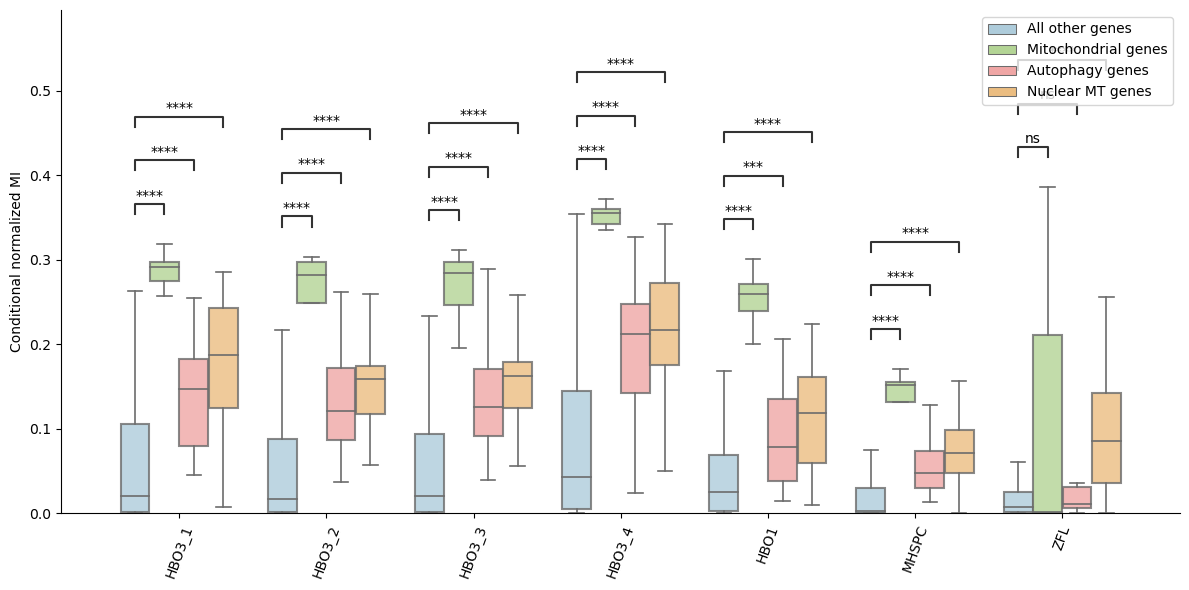

,dataset,gene_set,n_other,n_gene_set,p_raw,p_BH,significant_BH
0,HBO1,Autophagy genes,20800,18,1.131454e-04,1.250555e-04,True
1,HBO1,Mitochondrial genes,20800,13,1.743324e-09,1.477840e-08,True
2,HBO1,Nuclear MT genes,20800,25,1.803200e-08,3.442473e-08,True
3,HBO3_1,Autophagy genes,25293,18,1.388088e-05,1.619436e-05,True
4,HBO3_1,Mitochondrial genes,25293,13,3.180835e-09,1.477840e-08,True
5,HBO3_1,Nuclear MT genes,25293,25,2.350570e-09,1.477840e-08,True
6,HBO3_2,Autophagy genes,26798,18,3.553863e-06,4.664446e-06,True
7,HBO3_2,Mitochondrial genes,26798,13,8.164528e-09,1.905057e-08,True
8,HBO3_2,Nuclear MT genes,26798,25,3.938611e-09,1.477840e-08,True
9,HBO3_3,Autophagy genes,25934,18,5.201685e-06,6.425611e-06,True


BH correction performed jointly across 21 displayed comparisons.


,dataset,gene_set,n_other,n_gene_set,p_raw,p_BH,significant_BH
0,HBO3_1,Mitochondrial genes,25293,13,3.180835e-09,1.477840e-08,True
1,HBO3_1,Autophagy genes,25293,18,1.388088e-05,1.619436e-05,True
2,HBO3_1,Nuclear MT genes,25293,25,2.350570e-09,1.477840e-08,True
3,HBO3_2,Mitochondrial genes,26798,13,8.164528e-09,1.905057e-08,True
4,HBO3_2,Autophagy genes,26798,18,3.553863e-06,4.664446e-06,True
5,HBO3_2,Nuclear MT genes,26798,25,3.938611e-09,1.477840e-08,True
6,HBO3_3,Mitochondrial genes,25934,13,7.331436e-09,1.905057e-08,True
7,HBO3_3,Autophagy genes,25934,18,5.201685e-06,6.425611e-06,True
8,HBO3_3,Nuclear MT genes,25934,25,6.882927e-09,1.905057e-08,True
9,HBO3_4,Mitochondrial genes,23230,13,4.222401e-09,1.477840e-08,True


In [24]:
save_path = (
    "/fast/AG_Metzger/philipp/python_files/"
    "gene_signature/mutual_information_approach/"
    "November_25_ReDo/figures/"
    "all_datasets_conditional_mutual_information_"
    "all_gene_sets_with_stats_only_box_plot.pdf"
)

plot_conditional_mi_gene_sets(
    all_data=all_data,
    dataset_order=dataset_order,
    custom_palette=custom_palette,
    save_path=save_path
)